# Which method does better, and under which protocol? The methods of the benchmark compared on one protocol

**Question:** Two numbers from two protocols do not rank two methods, so how does the product put the methods it runs on one protocol per question, how does each metric decide which method is best, and what does that ranking never say about a method, a proposed one included?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 06 of this topic
- **Reading time:** about 80 minutes

## Objectives

By the end of this notebook you can:

- open the document `data/derived/benchmark/methods-compared.json` and say what a question, a run, a metric, a row and a cell hold, and why every value carries a path, a pointer and a hash;
- show with the document's own numbers why two protocols cannot be pooled into one ranking;
- write the five rules a metric can declare (lower, higher, nearer a target, nearer another metric, an order of categories) as equations, with ties kept and a null never ranked;
- show by simulation why a p-value is context and never a score;
- recompute the standings of the twelve questions from their cells by the declared rules and see them agree with the document's own;
- follow a cited value to its source file, resolve its JSON pointer as the builder does and compare its hash;
- count how often a method proposed in this work is the best and how often it is not, and name each negative result with the manuscript that reports it;
- read the truth status of each run and the null cells with their reasons, say where the comparison breaks, and place a method of your own beside a question's rows without presenting a number as comparable when its protocol differs.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 pandas==3.0.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The document is built by a step of the product's pipeline, `pipeline.benchmark.methods`, and the notebook imports that module for its readers (`pointer_get`, `sha256_of`) and for the function that picks the best row of a column (`best_of`) and the one that builds the standings (`standings_of`): one rule for the builder, the tests and this notebook, never a copy. The pipeline is plain scripts and not a package, so the next cell puts `data-pipeline/` on the import path first. The engine `riskvalidation` supplies the tests the notebook runs (Kupiec, the Basel zone, the AUC, the Brier score and the calibration error, the Spiegelhalter test). The notebook reads committed files only and never writes one. The cell prints the version of every package.

In [1]:
# Put the pipeline on the import path, import the methods-compared step and the engine, and print the versions
import importlib.metadata as md
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from riskvalidation.core.policy import default_policy
from riskvalidation.validation import calibration as cal, discrimination as disc, market
from scipy import stats

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.benchmark import methods as bm

LANG = "en"
STANDING = {
    "established": "long-established",
    "recent": "recent published",
    "proposed": "proposed in this work",
    "reference": "reference",
}


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


for name in ("riskvalidation", "numpy", "scipy", "pandas", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
pandas 3.0.6
matplotlib 3.11.2


## Data

The notebook reads one document and the committed case documents it cites.

- **The comparison:** `data/derived/benchmark/methods-compared.json`, contract `benchmark-methods`, written by the product's own step from committed case documents and committed manuscript result files; it computes nothing of its own.
- **The case documents the notebook follows:** `data/derived/C11/calm-2004-06.json` (VaR and ES forecasts, real outcomes; sources French data library, licence class `derived-only`, and the Treasury par curve and FRED, `mirror-allowed`), `data/derived/C04/withdrawals.json` (rating withdrawals, a generator of known truth), `data/derived/C01/holdout.json` (the Taiwan card holdout; source `uci-taiwan`, `mirror-allowed`), `data/derived/C06/rd-2006-12.json` and `data/derived/C08/dc-2003-06.json` (SBA loans, `mirror-allowed`), `data/derived/C16/lcr-standard.json` (the reverse liquidity stress, sources FDIC, Federal Reserve and Treasury, `mirror-allowed`).
- **The retail twin:** `data/derived/C01/german-twin.json`, the German Credit data, Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data, licence class `mirror-allowed` (CC BY 4.0). Its 50-applicant sample is what the last section scores.
- **Not read:** the manuscript result files that 200 of the document's cells cite live under `manuscripts/`, outside the folders a notebook may read; the notebook counts them and cannot follow them.

## Method

A benchmark that lists the numbers of several methods side by side compares nothing unless the numbers were produced under one protocol: the same data, the same split, the same seed, the same metric. The product's methods-compared document answers, for each of twelve questions, which method does better under one protocol, for the methods the product runs on it: the long-established ones, the recent published ones and the ones proposed in this work. The step that writes it recomputes nothing. It copies each value from a committed case document or manuscript result file and records beside it the file, the position of the value and the hash of the file, so any reader can check the copy. The notebook takes the document apart in eight steps and then turns to where it stops informing.

### Step 1: what the document holds

A question has runs (a protocol and a seed), metrics (each with the rule that says which value is better), rows (one per method, with its standing) and, in each row, cells (a value and its citation, or a null and its reason). The next cell opens the document and counts them.

In [2]:
# Open the document and count what it holds: questions, runs, metrics, rows and the cells that carry a number
document = read_json("data/derived/benchmark/methods-compared.json")
questions = {q["id"]: q for q in document["questions"]}
q1 = questions["Q1"]
cells = [c for q in document["questions"] for r in q["rows"] for c in r["cells"]]
print("contract version:", document["schema_version"], "| code version:", document["provenance"]["code_version"])
print("questions:", len(questions), "| questions not built:", [n["id"] for n in document["not_built"]])
print(
    "runs:",
    sum(len(q["runs"]) for q in questions.values()),
    "| metrics:",
    sum(len(q["metrics"]) for q in questions.values()),
)
print(
    "rows:",
    sum(len(q["rows"]) for q in questions.values()),
    "| cells:",
    len(cells),
    "| null cells:",
    sum(c["value"] is None for c in cells),
)
print("methods left out of every question:", len(document["left_out"]))

contract version: 2.0.0 | code version: 1.01.000
questions: 12 | questions not built: ['Q13', 'Q14']
runs: 18 | metrics: 63
rows: 95 | cells: 1844 | null cells: 150
methods left out of every question: 4


The document is the contract version 2.0.0, written by the code of release 1.01.000. It holds 12 questions (a thirteenth and a fourteenth are listed as not built, each with its reason), 18 runs, 63 metrics, 95 rows and 1,844 cells, 150 of them null, and it leaves four methods out of every question, each with its reason. The numbers say how much is there. The next cell lists the twelve questions with their case, their runs, their metrics and the number of methods by standing.

In [3]:
# One line per question: its title, the case it runs on, how many runs, metrics and methods, and the rows by
# standing
rows = []
for q in questions.values():
    by_standing = Counter(r["standing"] for r in q["rows"])
    rows.append(
        {
            "Q": q["id"],
            "question": q["title"][LANG][:52],
            "cases": ", ".join(q["case_ids"]),
            "runs": len(q["runs"]),
            "metrics": len(q["metrics"]),
            "methods": len(q["rows"]),
            "established": by_standing["established"],
            "recent": by_standing["recent"],
            "proposed": by_standing["proposed"],
            "reference": by_standing["reference"],
        }
    )
pd.DataFrame(rows).set_index("Q")

,question,cases,runs,metrics,methods,established,recent,proposed,reference
Q,,,,,,,,,
Q1,VaR and ES forecasts in stress windows,C11,1,7,22,11,7,3,1
Q2,Monitoring calibration and back-tests over time,"C22, C11, C03",4,11,7,4,0,3,0
Q3,P&L attribution of a trading desk,C13,1,2,3,1,0,2,0
Q4,PD under informative rating withdrawals,C04,1,6,5,2,0,1,2
Q5,Default prediction on a retail book,C01,2,8,9,2,5,0,2
Q6,Lifetime PD by survival models,C06,1,4,4,3,1,0,0
Q7,LGD on defaulted loans,C08,1,5,8,6,2,0,0
Q8,Operational-risk capital,C17,1,4,10,7,3,0,0
Q9,A behavioural assumption changed at a limit br...,C14,1,3,7,1,0,1,5


The twelve questions run from forecasts of a loss quantile (Q1, 22 methods on six stress windows) to the corrections of three validation tests (Q11, 8 methods in three experiments). The standing columns use the words of the page: Q1 has 11 long-established methods, 7 recent published ones, 3 proposed in this work and one reference; Q5 and Q6 have none proposed; Q9 has one proposed and five references. A reference is a comparator that runs on the protocol and has no method row of its own, and the document says whether it takes part in the ranking. The table does not say which method wins, only who is in the room. The next step shows why who is in the room must share a protocol.

### Step 2: why a comparison needs one protocol

Question 5, the default prediction of a retail book, has two runs. The Taiwan run scores every rung on a locked holdout of the Taiwan card file and the German run scores every rung on the German twin; both use the seed 42, both rest on real outcomes, and the rungs of one run share the same held-out rows. The document keeps the two as two runs with their own metrics (`tw_auc` and `de_auc`) because their numbers answer different questions. The next cell reads the AUC of each rung in each run.

In [4]:
# Two numbers from two protocols: the AUC of the retail rungs on the Taiwan holdout and on the German twin, run by
# run
def metric_values(question, metric):
    out = {}
    for row in question["rows"]:
        out[row["id"]] = {c["column"]: c["value"] for c in row["cells"] if c["metric"] == metric}
    return out


q5 = questions["Q5"]
taiwan, german = metric_values(q5, "tw_auc"), metric_values(q5, "de_auc")
auc = pd.DataFrame(
    {
        "Taiwan run": {k: list(v.values())[0] for k, v in taiwan.items() if v},
        "German run": {k: list(v.values())[0] for k, v in german.items() if v},
    }
)
print("rungs with an AUC in both runs:", int(auc.notna().all(axis=1).sum()))
print(
    "seeds of the two runs:",
    [r["seed"]["value"] for r in q5["runs"]],
    "| truth status:",
    [r["truth_status"] for r in q5["runs"]],
)
print("protocol, as the document states it:", q5["protocol"][LANG][:150])
auc.round(4)

rungs with an AUC in both runs: 7
seeds of the two runs: [42, 42] | truth status: ['real-outcomes', 'real-outcomes']
protocol, as the document states it: A locked stratified holdout of 30%, with repeated stratified five-fold cross-validation inside the training part; every rung of one document is scored


,Taiwan run,German run
P1-scorecard,0.7587,0.7883
P2a-l1,0.7587,0.7908
P2b-pltr,0.7749,0.7861
P3-ebm,0.7746,0.7874
P4-lightgbm,0.7770,0.7784
P4-xgboost,0.7755,NaN
P5-tabpfn,NaN,0.7769
P0-constant,0.5000,0.5000
P0-single,0.6917,0.7233


Seven rungs have an AUC in both runs, and the numbers are close enough to invite a mistake: the scorecard scores 0.7587 on Taiwan and 0.7883 on the German twin, LightGBM 0.7770 and 0.7784. The protocol the document states for the pair is one locked stratified holdout of 30 percent with repeated stratified five-fold cross-validation inside the training part, applied to a different file in each run. The table says that every rung of one column was scored under one protocol. It cannot say what happens when a reader takes numbers from two columns, which the next cell does.

In [5]:
# Compare the two runs the way a careless reader would, and then the way the protocol allows: inside one run
tw, de = "Taiwan run", "German run"
careless = auc.loc["P4-lightgbm", tw] - auc.loc["P1-scorecard", de]
inside_tw = auc.loc["P4-lightgbm", tw] - auc.loc["P1-scorecard", tw]
inside_de = auc.loc["P4-lightgbm", de] - auc.loc["P1-scorecard", de]
both = auc.dropna()
flips = 0
for i, a in enumerate(both.index):
    for b in both.index[i + 1 :]:
        flips += np.sign(both[tw][a] - both[tw][b]) * np.sign(both[de][a] - both[de][b]) < 0
print("LightGBM on Taiwan minus the scorecard on German:", round(float(careless), 4))
print("LightGBM minus the scorecard inside the Taiwan run:", round(float(inside_tw), 4))
print("LightGBM minus the scorecard inside the German run:", round(float(inside_de), 4))
print("pairs of rungs whose order differs between the runs:", int(flips), "/", len(both) * (len(both) - 1) // 2)

LightGBM on Taiwan minus the scorecard on German: -0.0113
LightGBM minus the scorecard inside the Taiwan run: 0.0183
LightGBM minus the scorecard inside the German run: -0.0099
pairs of rungs whose order differs between the runs: 10 / 21


A reader who sets LightGBM on Taiwan (0.7770) against the scorecard on the German twin (0.7883) reads a gap of $-0.0113$ and concludes that the scorecard is better. Inside the Taiwan run LightGBM beats the scorecard by $+0.0183$, and inside the German run the scorecard beats LightGBM by $0.0099$. So the cross-protocol gap has the sign of the German run and the size of neither. Across the seven rungs that have both numbers, 10 of the 21 pairs of rungs change order between the two runs. Two protocols give two orders, and a ranking built on a mixture of them is the ranking of the file as much as of the method. This is why the document splits a question into runs, gives each metric exactly one run, and refuses to let one file serve two runs of a question. The next step shows how a metric decides, inside one run, which row is best.

### Step 3: each metric declares its rule

Every metric of the document declares `better` once, and the standing of a column is generated from it. With $x_m$ the value of method $m$ in the column, $\mathcal{M}$ the set of rows that are ranked and have a value (a null is never ranked, and a row flagged as not ranked is shown and left out), the best rows under the five rules are

$$\hat{M}_{\mathrm{lower}} = \arg\min_{m \in \mathcal{M}} x_m, \qquad \hat{M}_{\mathrm{higher}} = \arg\max_{m \in \mathcal{M}} x_m, \qquad \hat{M}_{\mathrm{nearer}:a} = \arg\min_{m \in \mathcal{M}} \lvert x_m - a \rvert$$

with $a$ the number written in the rule, and for `nearer-metric:<m>` the same with $a$ taken from the column of the metric $m$ (the expected number of exceedances is the target of the observed number); for an order of categories $o = (c_1, c_2, \dots)$,

$$\hat{M}_{\mathrm{order}} = \arg\min_{m \in \mathcal{M}} \operatorname{pos}_o(x_m)$$

where $\operatorname{pos}_o$ is the position of the category in the list and a value outside the list is not ranked. Each $\arg\min$ is the set of all rows that reach the minimum: ties are kept, by exact equality of the stored numbers, and the document says `tie: true`. A metric declared `none` ranks nothing: every p-value is one. The next cell writes the five rules as a function of a column and runs it on a toy column with a tie and a null.

In [6]:
# The five rules of the document as code: the best cell of a column, ties kept and a null never ranked
def best_cells(rule, values, reference=None):
    live = {k: v for k, v in values.items() if v is not None}
    if rule == "none" or not live:
        return None
    if rule.startswith("order:"):
        order = rule[len("order:") :].split(",")
        rank = {k: order.index(v) for k, v in live.items() if v in order}
    else:
        number = {k: float(v) for k, v in live.items() if isinstance(v, (int, float))}
        target = reference if rule.startswith("nearer-metric:") else None
        target = float(rule.split(":")[1]) if rule.startswith("nearer:") else target
        sign = -1 if rule == "higher" else 1
        rank = {k: sign * v if rule in ("lower", "higher") else abs(v - target) for k, v in number.items()}
    if not rank:
        return None
    top = min(rank.values())
    return [k for k in values if rank.get(k) == top]


toy = {"a": 0.42, "b": 0.31, "c": 0.31, "d": None, "e": 0.55}
levels = {"a": "amber", "b": "green", "c": "green", "d": None}

The cell defines the function and two toy columns: a numeric one, $\{a: 0.42, b: 0.31, c: 0.31, d: \text{null}, e: 0.55\}$, with a tie and a null, and a column of categories. The next cell runs both through my function and through the step's own.

In [7]:
# The toy column through my function and through the step's own: ties stated, a null never ranked, the same winners
cases = [
    ("lower", toy, None),
    ("higher", toy, None),
    ("nearer:0.5", toy, None),
    ("nearer-metric:m", toy, 0.4),
    ("order:green,amber,red", levels, None),
]
rows = []
for rule, column, reference in cases:
    step_best, step_value = bm.best_of(rule, column, reference)
    mine = best_cells(rule, column, reference)
    rows.append(
        {"rule": rule, "the step": step_best, "its value": step_value, "mine": mine, "agree": step_best == mine}
    )
print("none:", best_cells("none", toy), bm.best_of("none", toy))
pd.DataFrame(rows).set_index("rule")

none: None None


,the step,its value,mine,agree
rule,,,,
lower,"[b, c]",0.31,"[b, c]",True
higher,[e],0.55,[e],True
nearer:0.5,[e],0.55,[e],True
nearer-metric:m,[a],0.42,[a],True
"order:green,amber,red","[b, c]",green,"[b, c]",True


On the toy column the rule `lower` returns both $b$ and $c$, the tie, and never $d$; `higher` returns $e$; `nearer:0.5` returns $e$ (distance 0.05); `nearer-metric` with a reference of 0.4 returns $a$ (distance 0.02); and the order rule puts both green rows first and ignores the null. The step's `best_of` returns the same winners as the function written above, with the value of the best cell, and the two agree in all five lines. A reader who needs to rank a column in their own code can call `best_of(rule, values, reference)` with a dictionary of row ids to values, and a rule of `none` returns nothing, as the last printed line shows. The order rule is read the same way, and the next step shows what an order of categories means on a real scale: the Basel zone.

### Step 4: an order of categories, and the ties it makes

The zone of the Basel traffic light is a function of the number of exceedances in a window of 250 days at the 99 percent level, and Q1's `zone_1` metric ranks the zones in the order green, amber, red. The engine computes the zone. The next cell calls it for 0 to 12 exceedances and then counts the zones the committed Q1 rows have in one window.

In [8]:
# The order rule: the engine's Basel zone for 0 to 12 exceedances in 250 days, and the counts that share a zone
rows = []
for count in range(13):
    hits = np.r_[np.ones(count), np.zeros(250 - count)].astype(int)
    result = market.basel_traffic_light(hits)
    rows.append({"exceedances": count, "zone": result.extras["zone"], "multiplier": result.extras["mar32_multiplier"]})
zones = pd.DataFrame(rows)
print(zones.groupby("zone")["exceedances"].agg(["min", "max", "count"]).reindex(["green", "amber", "red"]))
print(
    "real zones of Q1, 1% level, equities 2007 to 2009:",
    dict(
        Counter(
            c["value"]
            for r in q1["rows"]
            for c in r["cells"]
            if c["metric"] == "zone_1" and c["column"] == "equity-2007-09"
        )
    ),
)

       min  max  count
zone                  
green    0    4      5
amber    5    9      5
red     10   12      3
real zones of Q1, 1% level, equities 2007 to 2009: {'amber': 6, 'red': 6, 'green': 6, None: 3}


Counts of 0 to 4 are green, 5 to 9 amber and 10 or more red, so three categories group thirteen counts and every column of a zone metric is mostly ties: in the equities window of 2007 to 2009 the committed Q1 rows have six green, six amber and six red models (and three rows with no zone, whose reason the document gives). A rule that ranks by order therefore names a group, not a method, and the document says so with `tie: true` and the list of rows. The cell shows the scale and the group sizes. It does not show how far inside a zone a method is, which the exceedance count carries and the zone throws away.

### Step 5: a p-value is context, never a score

The document copies the Kupiec and the conditional-coverage p-values of every rule of Q1, and declares them `none`. A p-value measures the evidence against a null hypothesis, and when the null is true a continuous p-value is uniform on $[0, 1]$: $P(p \le u) = u$. A rule that is perfectly calibrated therefore has a p-value that is as likely to be 0.03 as 0.97, and among $n$ such rules the best p-value has expectation

$$\mathbb{E}\big[\max_{i \le n} p_i\big] = \frac{n}{n+1}, \qquad P(\text{rule } i \text{ has the best } p) = \frac{1}{n}$$

so ranking by p-value picks a winner among equally good rules by luck. The next cell draws 20,000 times the z-statistics of 18 calibrated rules, turns each into a two-sided p-value and counts who has the best.

In [9]:
# A p-value under its null is uniform: draw 18 calibrated rules, give each a z-test p-value, and see who has the
# best p
rng = np.random.default_rng(2026)
n_rules, n_runs = 18, 20000
z = rng.standard_normal((n_runs, n_rules))
p = 2 * stats.norm.sf(np.abs(z))
winner = p.argmax(axis=1)
share_best = np.bincount(winner, minlength=n_rules) / n_runs
ks = stats.kstest(p.ravel(), "uniform")
print("mean p-value:", round(float(p.mean()), 4), "| share of p below 0.05:", round(float((p < 0.05).mean()), 4))
print("Kolmogorov-Smirnov distance to the uniform:", round(float(ks.statistic), 4))
print(
    "share of runs in which each rule has the best p: smallest and largest:",
    round(float(share_best.min()), 4),
    round(float(share_best.max()), 4),
    "| 1/18 =",
    round(1 / 18, 4),
)
print(
    "mean of the best p among 18 calibrated rules:",
    round(float(p.max(axis=1).mean()), 4),
    "| 18/19 =",
    round(18 / 19, 4),
)

mean p-value: 0.5004 | share of p below 0.05: 0.0503
Kolmogorov-Smirnov distance to the uniform: 0.0013
share of runs in which each rule has the best p: smallest and largest: 0.0532 0.0614 | 1/18 = 0.0556
mean of the best p among 18 calibrated rules: 0.9475 | 18/19 = 0.9474


The simulated p-values have a mean of 0.5004 and 5.03 percent of them fall below 0.05, a Kolmogorov-Smirnov distance to the uniform of 0.0013; each of the 18 rules has the best p-value in between 5.32 and 6.14 percent of the runs, around $1/18 = 5.56$ percent; and the mean of the best p among 18 calibrated rules is 0.9475, against $18/19 = 0.9474$. A calibrated rule is crowned by its p-value as often as any other, and the winner of a run is a draw. The test the product actually uses is discrete, so the next cell repeats the experiment with the engine's own Kupiec test on 2,000 calibrated histories of 250 days at the 1 percent level.

In [10]:
# The same demonstration with the product's own Kupiec test: 2,000 calibrated 250-day histories at the 1% level
rng = np.random.default_rng(5)
kupiec_p = []
for _ in range(2000):
    hits = (rng.random(250) < 0.01).astype(int)
    kupiec_p.append(market.kupiec_pof(hits, 0.01).p_value)
kupiec_p = np.array(kupiec_p)
print("distinct p-values among 2,000 histories:", len(set(np.round(kupiec_p, 6))))
print(
    "mean p-value:", round(float(kupiec_p.mean()), 4), "| share below 0.05:", round(float((kupiec_p < 0.05).mean()), 4)
)

distinct p-values among 2,000 histories: 10
mean p-value: 0.4779 | share below 0.05: 0.0945


The Kupiec test of the engine compares the observed number of exceedances $x$ in $T$ days with the expected $\alpha T$ through the likelihood-ratio statistic

$$\mathrm{LR}_{\mathrm{POF}} = -2 \ln\!\big[(1-\alpha)^{T-x}\,\alpha^{x}\big] + 2 \ln\!\big[(1-x/T)^{T-x}\,(x/T)^{x}\big] \sim \chi^2_1$$

(Kupiec, 1995), and its p-value is the upper tail of that chi-square. With $T = 250$ and $\alpha = 0.01$ the count $x$ takes few values, so among 2,000 calibrated histories the p-value takes only 10 distinct values; its mean is 0.4779, not 0.5, and 9.45 percent fall below 0.05, not 5 percent, because a calibrated rule with no exceedance at all (which happens in 8 percent of the histories) already has $p = 0.025$. The same p-value would move a rule from "reject" to "keep" on a single exceedance. The next cell draws the three distributions: the continuous null, the engine's test under its null and the real Kupiec p-values the document copies for Q1.

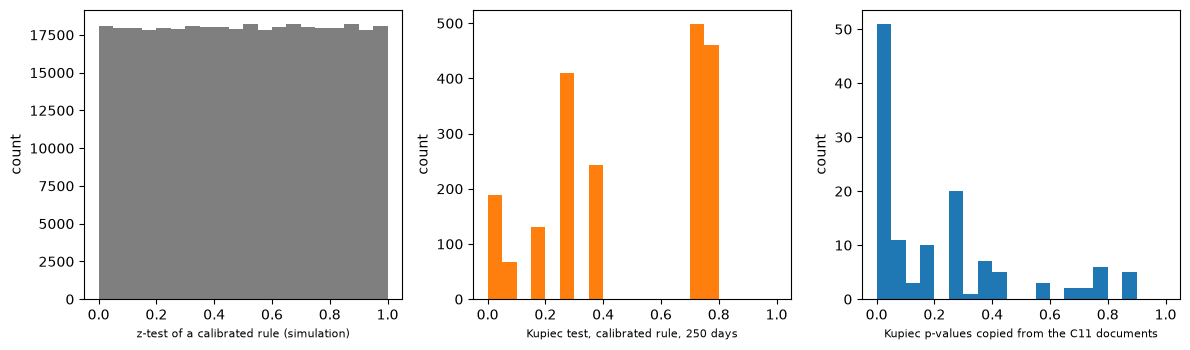

In [11]:
# Draw the three p-value distributions: the continuous null, the engine's Kupiec test under its null, the real
# Kupiec p-values of Q1
real = [c["value"] for r in q1["rows"] for c in r["cells"] if c["metric"] == "kupiec_1" and c["value"] is not None]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
panels = [
    (p.ravel(), "z-test of a calibrated rule (simulation)", "tab:gray"),
    (kupiec_p, "Kupiec test, calibrated rule, 250 days", "tab:orange"),
    (real, "Kupiec p-values copied from the C11 documents", "tab:blue"),
]
for ax, (values, label, colour) in zip(axes, panels):
    ax.hist(values, bins=20, range=(0, 1), color=colour)
    ax.set_xlabel(label, fontsize=8)
    ax.set_ylabel("count")
fig.tight_layout()
plt.show()

On the left the simulated p-values are flat across the twenty bins, as the equation says. In the middle the engine's Kupiec test under its null piles up on a handful of values, leaves most bins empty and puts more than a flat histogram would below 0.05. On the right the 126 real Kupiec p-values of Q1 (21 rules in six windows) are not flat at all: 40.5 percent fall below 0.05, because real rules are not calibrated in stress windows, and the figure cannot say which of them is better calibrated, only that many are rejected. The figure shows why the document keeps these numbers as context, on the page, and never in a standing. It does not show the rule that tests two things at once; the conditional-coverage p-value has the same status.

### Step 6: the standings of a question, recomputed

The document stores, for each metric and column, the best row or rows (`standings`). It is generated by the step, and a reader should not take it on faith. The next cell recomputes it from the cells of a question with the function written in step 3, using only the rows flagged as ranked and the rule each metric declares, and for `nearer-metric` the reference value of the same column.

In [12]:
# The standings of one question recomputed from its cells by the declared rules, with no help from the document's
# standings
def recompute(question):
    ranked = {r["id"] for r in question["rows"] if r["ranked"]}
    table = {}
    for row in question["rows"]:
        for c in row["cells"]:
            table.setdefault((c["metric"], c["column"]), {})[row["id"]] = c["value"]
    found = {}
    for metric in question["metrics"]:
        for column in metric["columns"]:
            values = {k: v for k, v in table.get((metric["id"], column), {}).items() if k in ranked}
            rule = metric["better"]
            reference = None
            if rule.startswith("nearer-metric:"):
                shown = [v for v in table[(rule.split(":")[1], column)].values() if isinstance(v, (int, float))]
                reference = float(shown[0])
            winners = best_cells(rule, values, reference)
            if winners is not None:
                found[(metric["id"], column)] = tuple(winners)
    return found

The function returns a dictionary from (metric, column) to the tuple of best rows. It is applied to the twelve questions in the next cell, which asserts that the result is equal to the document's standings, ties included.

In [13]:
# Compare my standings with the document's for the twelve questions: they must agree, ties included
rows = []
for qid, q in questions.items():
    mine = recompute(q)
    theirs = {(s["metric"], s["column"]): tuple(s["best"]) for s in q["standings"]}
    rows.append(
        {
            "Q": qid,
            "standings in the document": len(theirs),
            "recomputed here": len(mine),
            "equal": mine == theirs,
            "ties": sum(len(v) > 1 for v in theirs.values()),
        }
    )
agreement = pd.DataFrame(rows).set_index("Q")
assert agreement["equal"].all(), "the recomputed standings differ from the document's"
print("questions that agree:", int(agreement["equal"].sum()), "of", len(agreement))
agreement.T

questions that agree: 12 of 12


Q,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12
standings in the document,21,26,6,12,6,24,30,12,9,3,6,12
recomputed here,21,26,6,12,6,24,30,12,9,3,6,12
equal,True,True,True,True,True,True,True,True,True,True,True,True
ties,7,3,5,4,0,0,0,0,3,0,0,0


The assertion holds for all twelve questions: 167 standings in the document, 167 recomputed here, 22 of them ties. Q1 has 21 standings for four ranked metrics in six windows, fewer than the 24 a full grid would give, because the zone metric has no value in three of the windows (equities 2020, rates 2022 and mixed 2023); Q7 has 30 and Q10 has 3. The agreement is what the test suite of the product also checks with an independent recomputation, and it means the document's reading is a function of its cells and of nothing else. The table does not show that the cells are right, which is the subject of the following step. The next cell calls the step's own `standings_of` on the cells of Q1.

In [14]:
# The step's own standings function on the cells of Q1, set against the document: the same cells, the same rule, the
# same answer
rows_q1 = [{"id": r["id"], "ranked": r["ranked"], "cells": r["cells"]} for r in q1["rows"]]
metrics_q1 = [{"id": m["id"], "better": m["better"], "columns": m["columns"]} for m in q1["metrics"]]
recomputed = bm.standings_of(metrics_q1, rows_q1)
print("standings from the step:", len(recomputed), "| equal to the document's:", recomputed == q1["standings"])
print(
    "Q1 ranks:",
    len({m["id"] for m in q1["metrics"] if m["better"] != "none"}),
    "metrics and leaves as context:",
    [m["id"] for m in q1["metrics"] if m["better"] == "none"],
)

standings from the step: 21 | equal to the document's: True
Q1 ranks: 4 metrics and leaves as context: ['expected_1', 'kupiec_1', 'cc_1']


The step's function returns 21 standings on the cells of Q1, and they are equal to the document's. Q1 ranks four metrics (the two FZ0 losses, the distance of the exceedance count from its expected value, the zone) and leaves three as context: the expected count, which is the target of another metric, and the two p-values. The rules and the document agree, so the next question is whether the cells themselves are the numbers of the case documents.

### Step 7: following a cited value to its source

Every value of the document carries `cited`: the repository path of the file it was copied from, the RFC 6901 pointer of the value inside it and the SHA-256 of the file (with line endings normalised to LF). The next cell picks, for six questions, the first cell that cites a committed case document, opens that file, resolves the pointer with the builder's own `pointer_get` and compares the value found with the value in the document, and the hash of the file with the cited one.

In [15]:
# Follow a cited value to its source: read the file, resolve the pointer as the builder does, compare the value and
# the hash
def first_cited(question):
    for row in question["rows"]:
        for c in row["cells"]:
            if c["cited"] and c["cited"]["path"].startswith("data/derived/") and c["value"] is not None:
                return row["id"], c


columns = ["Q", "method", "cited file", "pointer", "document", "at the pointer", "same value", "same hash"]
rows = []
for qid in ("Q1", "Q4", "Q5", "Q6", "Q7", "Q10"):
    method, c = first_cited(questions[qid])
    cited = c["cited"]
    found = bm.pointer_get(read_json(cited["path"]), cited["pointer"])
    same_hash = bm.sha256_of(ROOT / cited["path"]) == cited["sha256"]
    rows.append(
        (qid, method, cited["path"][13:], cited["pointer"][-34:], c["value"], found, found == c["value"], same_hash)
    )
pd.DataFrame(rows, columns=columns).set_index("Q")

,method,cited file,pointer,document,at the pointer,same value,same hash
Q,,,,,,,
Q1,awhs,C11/calm-2004-06.json,tputs/models/2/by_level/0/fz0_mean,-4.490763,-4.490763,True,True
Q4,industry,C04/withdrawals.json,gns/0/treatments/0/coverage/5/rate,0.865000,0.865000,True,True
Q5,P1-scorecard,C01/holdout.json,/tests/26/metric,0.758722,0.758722,True,True
Q6,L0-km,C06/rd-2006-12.json,rung_comparison/0/integrated_brier,0.041392,0.041392,True,True
Q7,L1-ols,C08/dc-2003-06.json,/outputs/rung_comparison/0/rmse,0.296554,0.296554,True,True
Q10,lcr,C16/lcr-standard.json,tputs/scoring/denominators/0/ratio,0.506405,0.506405,True,True


Six cells of six questions, taken from six different case documents, point to a value that is the same number and to a file whose hash is the cited one. Q1's first method, age-weighted historical simulation, has a mean FZ0 loss of $-4.490763$ at the pointer `/outputs/models/2/by_level/0/fz0_mean` of the calm window of 2004 to 2006; the cohort estimator of Q4 that removes the withdrawn ratings covers 0.865 at its position in the withdrawals document; the scorecard of Q5 has a Taiwan AUC of 0.758722 at `/tests/26/metric`. The table shows six copies verified. It does not show all of them: the next cell counts where the 1,844 cells point.

In [16]:
# Count where every cell of the document points: committed case documents the notebook can open, manuscript result
# files it cannot
where = Counter()
for c in cells:
    if c["cited"]:
        where[
            "data/derived" if c["cited"]["path"].startswith("data/derived/") else c["cited"]["path"].split("/")[0]
        ] += 1
    else:
        where["null, no citation"] += 1
print(dict(where))
print(
    "distinct files read by the builder:",
    len(document["provenance"]["documents"]),
    "| rule of the hash:",
    document["provenance"]["hash_rule"],
)

{'data/derived': 1618, 'null, no citation': 26, 'manuscripts': 200}
distinct files read by the builder: 48 | rule of the hash: SHA-256 of the file with line endings normalised to LF


Of the 1,844 cells, 1,618 cite a committed case document that the notebook can open, 200 cite a manuscript result file under `manuscripts/` (the experiments of questions 2, 4, 9, 11 and others, which a notebook cannot read), and 26 are null with no citation. The builder read 48 distinct files in all, and the rule of the hash is stated in the document: the SHA-256 of the file with line endings normalised to LF, so that a checkout on Windows hashes as one on Linux. The product's tests re-read every cell on every run, so a re-baked case whose numbers moved fails until the step is rerun; this notebook follows six. The count shows the provenance of the whole document. It does not verify the 200 manuscript cells, which another reader has to open.

### Step 8: reading the comparison

Four views read the document. The first is the bars of one metric of one question by method, grouped by standing: the mean FZ0 loss at the 1 percent level of the 18 methods of Q1 that have the loss (10 long-established, 5 recent published and 3 proposed) in the equities window of 2007 to 2009, with the best marked.

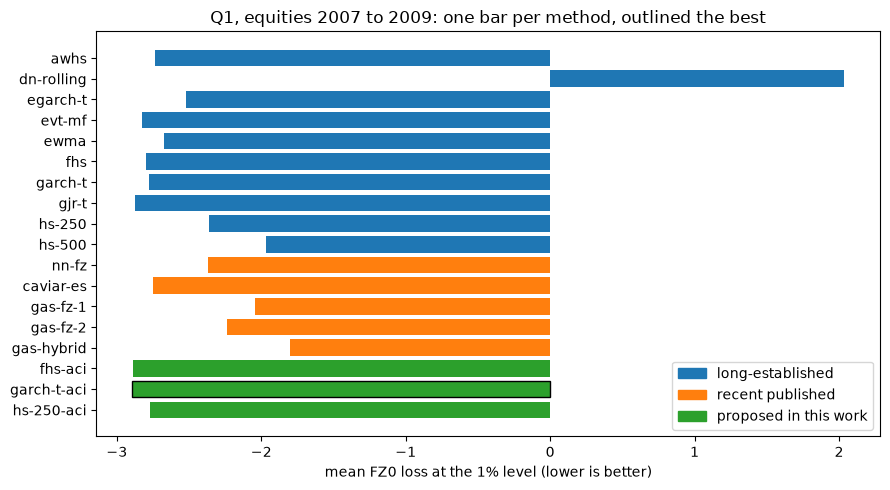

In [17]:
# Bars of one metric of one question by method: the mean FZ0 loss of the 18 rules of Q1 in one window, grouped by
# standing
metric, window = "fz0_1", "equity-2007-09"
values = {
    r["id"]: next((c["value"] for c in r["cells"] if c["metric"] == metric and c["column"] == window), None)
    for r in q1["rows"]
}
standing = {r["id"]: r["standing"] for r in q1["rows"]}
order = [k for s in ("established", "recent", "proposed") for k in values if standing[k] == s and values[k] is not None]
best = next(s["best"] for s in q1["standings"] if s["metric"] == metric and s["column"] == window)
colour = {"established": "tab:blue", "recent": "tab:orange", "proposed": "tab:green"}
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    order,
    [values[k] for k in order],
    color=[colour[standing[k]] for k in order],
    edgecolor=["black" if k in best else "none" for k in order],
)
ax.invert_yaxis()
ax.set_xlabel("mean FZ0 loss at the 1% level (lower is better)")
ax.set_title("Q1, equities 2007 to 2009: one bar per method, outlined the best")
handles = [plt.Rectangle((0, 0), 1, 1, color=colour[s]) for s in colour]
ax.legend(handles, [STANDING[s] for s in colour], loc="lower right")
fig.tight_layout()
plt.show()

The bars are grouped by standing: the long-established methods in blue, the recent published ones in orange and the three proposed in this work in green, and the best, outlined in black, is the proposed GARCH(1,1) with Student-t errors and adaptive conformal recalibration (`garch-t-aci`), with a loss of $-2.894$, followed by the proposed filtered historical simulation with the same recalibration (`fhs-aci`) at $-2.886$ and by a long-established GJR-GARCH (`gjr-t`) at $-2.876$. The bars carry the ids of the document's rows. The loss is lower-is-better, so a longer bar to the left is better. The methods of one group are not clustered at one end: the third proposed method has four long-established bars above it, so the group tells how old a method is and not how well it does. The first gap, 0.008, is also one the rounding of the next section would turn into a tie at two decimals. The figure shows one metric in one window. It does not show whether the proposed method is the best in the other five windows, which the document's standings say it is not.

The second view asks the question the document exists to answer for the product's own methods: how often is a method proposed in this work the best on a ranked metric, and how often is it not. The next cell counts, for each question that has a ranked proposed method, the ranked cells (metric by column) whose best row is a proposed one, ties included.

In [18]:
# How often a method proposed in this work is the best on a ranked metric, question by question, from the standings
rows = []
for qid, q in questions.items():
    proposed = {r["id"] for r in q["rows"] if r["standing"] == "proposed" and r["ranked"]}
    scored = [s for s in q["standings"] if proposed]
    won = sum(bool(proposed & set(s["best"])) for s in scored)
    rows.append(
        {
            "Q": qid,
            "proposed methods": len(proposed),
            "ranked cells": len(scored),
            "best": won,
            "not best": len(scored) - won,
        }
    )
proposed_table = pd.DataFrame(rows).set_index("Q")
print("cells with a proposed method in the question:", int(proposed_table["ranked cells"].sum()))
print("best:", int(proposed_table["best"].sum()), "| not best:", int(proposed_table["not best"].sum()))
print("questions with no proposed method:", proposed_table.index[proposed_table["proposed methods"] == 0].tolist())
proposed_table.T

cells with a proposed method in the question: 80
best: 30 | not best: 50
questions with no proposed method: ['Q5', 'Q6', 'Q7', 'Q8', 'Q10', 'Q12']


Q,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12
proposed methods,3,3,2,1,0,0,0,0,1,0,3,0
ranked cells,21,26,6,12,0,0,0,0,9,0,6,0
best,7,3,5,8,0,0,0,0,4,0,3,0
not best,14,23,1,4,0,0,0,0,5,0,3,0


Six of the twelve questions (Q5, Q6, Q7, Q8, Q10 and Q12) have no ranked proposed method: they compare long-established and recent published ones, and the document keeps them for that reason. In the six that have one there are 80 ranked cells, and a proposed method is the best in 30 of them and not the best in 50. The split is uneven: Q4 has 8 of 12, Q3 has 5 of 6, Q9 has 4 of 9, Q1 has 7 of 21, Q11 has 3 of 6 and Q2 has 3 of 26. The table counts cells and not questions, so a question with many columns weighs more. It does not say why a proposed method loses where it does, which the next two cells and the manuscripts say.

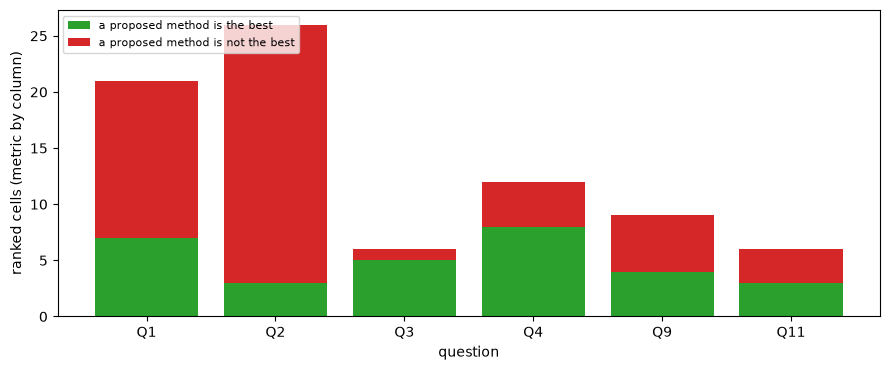

In [19]:
# Draw the table above: for each question, the cells where a proposed method is the best and the cells where it is
# not
shown = proposed_table[proposed_table["ranked cells"] > 0]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(shown.index, shown["best"], color="tab:green", label="a proposed method is the best")
ax.bar(shown.index, shown["not best"], bottom=shown["best"], color="tab:red", label="a proposed method is not the best")
ax.set_xlabel("question")
ax.set_ylabel("ranked cells (metric by column)")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

Green is the part of the ranked cells of each question where a proposed method is the best, and red the part where it is not. Q3 is almost all green and Q2 almost all red; Q4 is two-thirds green; Q1 is one-third green. The figure shows the whole picture of the product's own methods at once, losses included, and it is what the document is for: a method proposed in this work that does not win is shown not winning. It does not show the size of any loss or win, only whether one occurred. The next cell names each loss in words, with the concept DOI of the manuscript that reports it.

In [20]:
# Each negative result in words, with the concept DOI link the document carries for the manuscript that reports it
for q in questions.values():
    for item in q["negative_results"]:
        print(q["id"], "|", ", ".join(item["rows"]), "|", "https://doi.org/" + item["concept_doi"])
        print("   ", item["text"][LANG])

Q2 | e_rate, e_cluster, e_battery | https://doi.org/10.5281/zenodo.24053173
    The manuscript reports a partial result: the size is held under optional stopping, but the delay and the power-cost clauses are not met at a hit rate of three times over twenty seeds and hold at four times.
Q4 | anchored | https://doi.org/10.5281/zenodo.24053159
    The committed verdict is refuted on both clauses: the anchored interval does not cover better than Manski's band, which covers as often with a wider interval, and the anchored parameter is not stable across years.
Q9 | engine | https://doi.org/10.5281/zenodo.24053161
    The breach test as the engine reads a stated parameter flags unrelated changes far above the nominal 5%, where the calibrated break-in-level tests stay near it; the table shows it losing on false flags.
Q11 | shift-permutation | https://doi.org/10.5281/zenodo.24053187
    The permutation reference detects a two-standard-deviation shift less often than the fixed drop of 0.05, bec

Four negative results are listed, one for each question where a proposed method loses and the manuscript says so: Q2, where the e-process monitors keep their size under optional stopping but do not meet the delay and the power-cost clauses at a hit rate of three times (https://doi.org/10.5281/zenodo.24053173); Q4, where the anchored interval is refuted on both clauses (https://doi.org/10.5281/zenodo.24053159); Q9, where the engine's breach test flags unrelated changes far above the nominal 5 percent (https://doi.org/10.5281/zenodo.24053161); and Q11, where the permutation reference detects a two-standard-deviation shift less often than the fixed drop of 0.05 (https://doi.org/10.5281/zenodo.24053187). The text of each is the document's, in the language of the tree. The titles of the manuscripts live in `product.json`, which a notebook may not read, so the links are the concept DOIs the document carries. The cell does not say which manuscript is better, only which reports a loss.

The third view is the truth status of each run, a fact copied from the case documents the run cites and, for a run that cites only manuscript files, declared with its reason. It tells a reader what a win means: on `real-outcomes` the metric is measured on what happened; on `synthetic-known-truth` it is measured against a generator whose truth is set by the experimenter; on `synthetic-calibrated` the data are shaped to a real event. The next cell counts the runs and the standings by status.

In [21]:
# The truth status of every run: what its data rest on, and how many standings of the document come from each kind
# of run
runs = pd.DataFrame(
    [{"Q": q["id"], "run": r["id"], "status": r["truth_status"]} for q in questions.values() for r in q["runs"]]
)
run_of = {(q["id"], m["id"]): m["run_id"] for q in questions.values() for m in q["metrics"]}
status_of = {(q["id"], r["id"]): r["truth_status"] for q in questions.values() for r in q["runs"]}
per_standing = Counter(
    status_of[(q["id"], run_of[(q["id"], s["metric"])])] for q in questions.values() for s in q["standings"]
)
print("runs by truth status:", runs["status"].value_counts().to_dict())
print("ranked standings by truth status:", dict(per_standing))
runs.groupby("status")["Q"].apply(lambda s: ", ".join(sorted(set(s)))).to_frame("questions")

runs by truth status: {'synthetic-known-truth': 9, 'real-outcomes': 8, 'synthetic-calibrated': 1}
ranked standings by truth status: {'real-outcomes': 93, 'synthetic-known-truth': 71, 'synthetic-calibrated': 3}


,questions
status,
real-outcomes,"Q1, Q12, Q2, Q5, Q6, Q7"
synthetic-calibrated,Q10
synthetic-known-truth,"Q11, Q2, Q3, Q4, Q8, Q9"


Of the 18 runs, 9 rest on a generator of known truth, 8 on real outcomes and one, the reverse liquidity stress of Q10, on a calibrated synthetic run. Of the document's ranked standings 93 come from real outcomes, 71 from known truth and 3 from the calibrated run. The status changes how a win is read. A proposed method that wins on a generator (Q3, Q4, Q8, Q9) has shown that it recovers a truth the experimenter set; one that wins on real windows (Q1) has shown it in the one history that happened; and a question that mixes the kinds, as Q2 does, keeps them as separate runs and never ranks the real ones. The table lists the questions by status. It does not say whether a generator resembles the world, which is a question for each case's design.

The fourth view counts the null cells. A cell the product does not have is null, with its reason, and nothing is estimated in its place. The next cell counts them by the reason the document gives and by question.

In [22]:
# Count the null cells by the reason the document gives, and by question
nulls = [
    (q["id"], c["null_reason"][LANG])
    for q in questions.values()
    for r in q["rows"]
    for c in r["cells"]
    if c["value"] is None
]
reasons = Counter(reason for _, reason in nulls)
print(
    "null cells:",
    len(nulls),
    "| distinct reasons:",
    len(reasons),
    "| null cells with no reason:",
    sum(not r for _, r in nulls),
)
by_question = pd.Series(Counter(qid for qid, _ in nulls)).reindex(list(questions)).fillna(0).astype(int)
for reason, n in reasons.most_common(4):
    print(n, "|", reason[:110])

null cells: 150 | distinct reasons: 14 | null cells with no reason: 0
37 | the median stream is never flagged within the horizon
36 | the rule forecasts no expected shortfall, so its FZ0 loss is undefined
18 | the case document gives no p-value for this model in this window and states: not evaluated: no exceedance
18 | the conformal block carries no Basel zone


There are 150 null cells and 14 distinct reasons, and no null cell lacks its reason. The commonest is that the median stream is never flagged within the horizon (37 cells: a monitor that never fires has no first-flag day), then that the rule forecasts no expected shortfall, so its FZ0 loss is undefined (36), that the case document gives no p-value for a model in a window and says it was not evaluated because it had no exceedance (18), and that the conformal block carries no Basel zone (18). Each says why a number is absent and none is a zero. The next figure draws them against all cells.

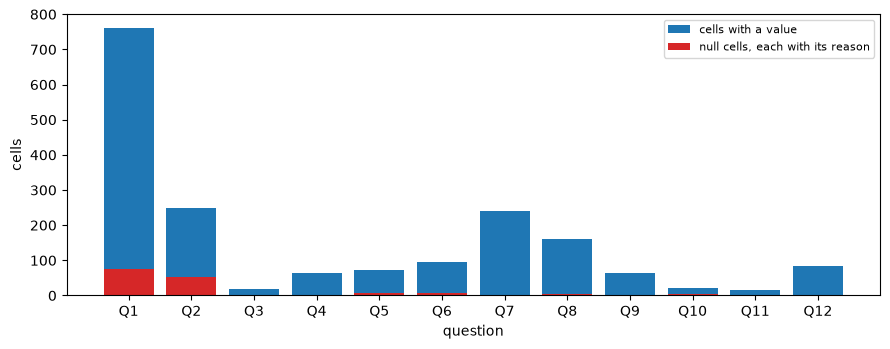

In [23]:
# Draw the null cells against all cells of each question
total = pd.Series({q["id"]: sum(len(r["cells"]) for r in q["rows"]) for q in questions.values()})
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(total.index, total.values, color="tab:blue", label="cells with a value")
ax.bar(by_question.index, by_question.values, color="tab:red", label="null cells, each with its reason")
ax.set_xlabel("question")
ax.set_ylabel("cells")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

Red is the share of null cells inside the cells of each question. Q1 (75 of 762 cells) and Q2 (54 of 250) carry 129 of the 150, because their methods differ most in what they can forecast: a rule with no expected-shortfall forecast has no FZ0 loss, and a monitor that never fires has no delay. A null is never ranked and never replaced, so a method with nulls competes on fewer columns, and the standing the reader sees is over the cells that exist. The figure shows where nulls live. It does not show whether a null hides a weakness: a method whose best columns are the only ones it has is ranked on strength alone, and the notes of each row in the document say so where it matters.

### Where the comparison breaks

The comparison is only as informative as its rules, and five things limit what it says. Each is shown with code on the document.

**Rounding that hides a tie.** The tie rule is exact equality of the stored numbers, and the page shows rounded numbers. The next cell scans the 167 standings for the columns where the best two exact values differ and agree once rounded to three decimals.

In [24]:
# Where rounding hides a tie: the columns where the best two exact values differ but agree once rounded to three
# decimals
hidden = []
for qid, q in questions.items():
    ranked = {r["id"] for r in q["rows"] if r["ranked"]}
    table = {}
    for row in q["rows"]:
        for c in row["cells"]:
            table.setdefault((c["metric"], c["column"]), {})[row["id"]] = c["value"]
    for s in q["standings"]:
        metric = next(m for m in q["metrics"] if m["id"] == s["metric"])
        if metric["better"] not in ("lower", "higher") or s["tie"]:
            continue
        numbers = sorted(
            (v for k, v in table[(s["metric"], s["column"])].items() if k in ranked and isinstance(v, (int, float))),
            reverse=metric["better"] == "higher",
        )
        if len(numbers) > 1 and numbers[0] != numbers[1] and round(numbers[0], 3) == round(numbers[1], 3):
            hidden.append((qid, s["metric"], s["column"], numbers[0], numbers[1]))
exact_ties = sum(s["tie"] for q in questions.values() for s in q["standings"])
print("standings in all:", sum(len(q["standings"]) for q in questions.values()), "| exact ties stated:", exact_ties)
print("columns where the best two differ but agree at three decimals:", len(hidden))
pd.DataFrame(hidden[:6], columns=["Q", "metric", "column", "best", "second"])

standings in all: 167 | exact ties stated: 22
columns where the best two differ but agree at three decimals: 21


,Q,metric,column,best,second
0,Q1,fz0_25,calm-2004-06,-4.658793,-4.658646
1,Q4,width,first_year,0.009690,0.010339
2,Q4,width,capture70,0.009690,0.010339
3,Q4,width,first_year_x10,0.003079,0.003277
4,Q5,tw_brier,holdout,0.135933,0.136100
5,Q6,ibs,2006-12,0.041187,0.041364


Of the 167 standings 22 are exact ties, and in 21 more columns the best two values differ but read the same at three decimals. In Q1's 2.5 percent loss for the calm window the best two are $-4.658793$ and $-4.658646$; in Q4 the best interval widths are 0.009690 and 0.010339, both 0.010; in Q5 the Taiwan Brier scores are 0.135933 and 0.136100, both 0.136; and in Q6 the integrated Brier scores are 0.041187 and 0.041364, both 0.041. A reader who rounds sees a tie where the document names a winner, and a reader who trusts the winner sees a difference that is smaller than the noise of the run (the AUC section below shows how large the noise of a protocol is). The document keeps the exact number and the tie rule; it does not claim the difference is significant. The table shows where the winner is a matter of the fourth decimal.

**A metric that is context.** The p-values are kept out of the standings because they are not scores. The next cell asks what the winner of each Q1 window would be if the Kupiec p-value were ranked as higher-is-better, and compares it with the winner by the FZ0 loss that the document does rank.

In [25]:
# A metric the document keeps as context: what ranking the Kupiec p-value would say, set against the loss that is
# ranked
rows = []
for window in q1["metrics"][0]["columns"]:
    p_by_rule = {
        r["id"]: next(c["value"] for c in r["cells"] if c["metric"] == "kupiec_1" and c["column"] == window)
        for r in q1["rows"]
        if r["ranked"]
    }
    ranked_best = next(s["best"] for s in q1["standings"] if s["metric"] == "fz0_1" and s["column"] == window)
    by_p = best_cells("higher", p_by_rule)
    rows.append(
        {
            "window": window,
            "best by the FZ0 loss": ranked_best[0],
            "best if the Kupiec p were ranked": by_p[0] if by_p else "-",
            "same method": bool(by_p) and by_p[0] == ranked_best[0],
        }
    )
pd.DataFrame(rows).set_index("window")

,best by the FZ0 loss,best if the Kupiec p were ranked,same method
window,,,
calm-2004-06,gjr-t,evt-mf,False
equity-2007-09,garch-t-aci,garch-t-aci,True
equity-2020,fhs,evt-mf,False
rates-2022,ewma,cf-rolling,False
fx-2008,caviar-es,egarch-t,False
mixed-2023,garch-t-aci,nn-fz,False


In five of the six windows the method with the best Kupiec p-value is not the one with the best FZ0 loss; only in the equities window of 2007 to 2009 do they coincide, on the proposed adaptive-conformal GARCH. The ranking by p-value would crown the extreme-value model in the calm window and in 2020, the Cornish-Fisher rule in 2022, the EGARCH in 2008 and the neural network in 2023: four different winners across five windows, none with a claim of its own. The table shows the disagreement between a score and a test. It does not show which of the two ranks the better forecast; the page keeps both, one as the standing and the other as context.

**Runs that must not be pooled.** Q2 keeps two generator runs apart, the case generator (seed 42) and the manuscript generator (seed 20261104), each with its own files. The next cell lists the best rule per column for the median first-flag day in each and checks that no file serves both.

In [26]:
# Two runs that must not be pooled: the winners of Q2 on the case generator (seed 42) and on the manuscript
# generator
q2 = questions["Q2"]
rows = []
for metric in ("gen_median", "man_median"):
    for s in (s for s in q2["standings"] if s["metric"] == metric):
        rows.append({"metric": metric, "column": s["column"], "best": ", ".join(s["best"]), "value": s["value"]})
table = pd.DataFrame(rows)
seeds = {r["id"]: r["seed"]["value"] if r["seed"] else None for r in q2["runs"]}
files = {r["id"]: set(r["files"]) for r in q2["runs"]}
print("seeds of the runs of Q2:", seeds)
print("files that two runs of Q2 share:", sorted(files["generator"] & files["manuscript"]))
same = [c for c in table["column"].unique() if table[(table["column"] == c)]["best"].nunique() == 1]
print("columns where both runs name the same best method:", len(same), "of", table["column"].nunique())
table.pivot(index="column", columns="metric", values="best")

seeds of the runs of Q2: {'generator': 42, 'manuscript': 20261104, 'real-windows': None, 'vintages': None}
files that two runs of Q2 share: []
columns where both runs name the same best method: 5 of 6


metric,gen_median,man_median
column,,
cluster-0.1,kupiec_trailing,kupiec_trailing
cluster-0.2,kupiec_trailing,independence_trailing
cluster-0.4,kupiec_cumulative,kupiec_cumulative
rate-x2,traffic_light,traffic_light
rate-x3,kupiec_cumulative,kupiec_cumulative
rate-x4,kupiec_cumulative,kupiec_cumulative


The two runs share no file, and in five of the six columns they name the same best rule. In the column `cluster-0.2` they do not: the case generator names the trailing Kupiec test and the manuscript generator the trailing independence test. If the two were pooled into one column the document would have to choose, or average two seeds of two generators that differ in design; keeping them apart lets the reader see that the order is stable in five of six cells and not in the sixth. The table shows an agreement that pooling would have hidden. It does not say which generator is closer to real streams, which is why the real windows and vintages of Q2 are shown and never ranked.

**A method left out, and why.** Not every method of the product is in a question. The document lists four methods it leaves out of every question and two questions it does not build, each with its reason. The next cell prints them.

In [27]:
# The methods the document leaves out of every question, and the questions it does not build, with their reasons in
# words
for item in document["left_out"]:
    print("-", item["method"][LANG], ":", item["reason"][LANG][:150])
for item in document["not_built"]:
    print("-", item["id"], item["title"][LANG], ":", item["reason"][LANG][:150])

- IFRS 9 expected-credit-loss engine : No competing method runs on a protocol: the weighted-scenario loss is committed beside the mean-path loss, but there is no outcome to score and no inc
- Conditional-forecast and growth-at-risk quantile satellites : No numbers are committed: the stress document holds only the linear and probit satellites.
- PD curve calibration carried to a new period : The scaled approaches take the new period's PD as an input, so there is nothing to rank (question 13 is not built).
- The published size and power studies of the validation tests, rerun : They reproduce published cells and do not compete with another method on a common stream.
- Q13 PD curve carried to a new period : The scaled approaches are given the new period's PD as an input and rescale the curve, so their forecast equals the observed PD and cannot be ranked a
- Q14 Portfolio loss quantile by method : No truth exists for a portfolio loss quantile, so the methods can be compared by their dispers

The four methods left out have four reasons: the IFRS 9 expected-credit-loss engine has no outcome to score and no competing method on a protocol; the growth-at-risk quantile satellites have no committed numbers; the PD curve calibration carried to a new period takes the new period's PD as an input, so there is nothing to rank; and the published size and power studies of the validation tests reproduce published cells and do not compete with another method on a common stream. The two questions not built, Q13 and Q14, say that the scaled approaches' forecast equals the observed PD, and that no truth exists for a portfolio loss quantile, so only dispersion can be compared. A method that is absent from the comparison is not thereby weaker, and the comparison says nothing about it. The list shows the edges of what the document covers. It does not say whether a later release fills them.

**A standing says how old a method is, not how good.** The words of the page (long-established, recent published, proposed in this work) come from the tier of the method's row in the product's design, read by code and never typed per row. They classify a method's origin. The next cell counts, over all questions, how many ranked rows each standing has and how many standings its rows win, ties counted for each method tied.

In [28]:
# A standing says how old a method is: how many ranked rows each standing has and how many standings it wins, ties
# counted for each
standing_of = {(q["id"], r["id"]): r["standing"] for q in questions.values() for r in q["rows"] if r["ranked"]}
wins = Counter(
    standing_of[(q["id"], b)]
    for q in questions.values()
    for s in q["standings"]
    for b in s["best"]
    if (q["id"], b) in standing_of
)
size = Counter(standing_of.values())
table = pd.DataFrame({"ranked rows": size, "standings won": wins}).fillna(0).astype(int)
table["wins per row"] = (table["standings won"] / table["ranked rows"]).round(2)
table.index = [STANDING[s] for s in table.index]
table

,ranked rows,standings won,wins per row
long-established,44,133,3.02
recent published,24,45,1.88
proposed in this work,13,40,3.08
reference,7,10,1.43


The 44 long-established rows win 133 standings, 3.02 per row; the 13 proposed rows win 40, 3.08 per row; the 24 recent published rows win 45, 1.88 per row; and the 7 reference rows win 10, 1.43 per row. The rates of the long-established and of the proposed rows are nearly equal and well above the recent published ones: age predicts nothing about rank. These counts also depend on where a row is entered: a row in a question with many columns wins more. The table says that a standing is a label of origin and that no ordering of quality follows from it. It does not say that a proposed method is better, and the previous sections showed it is not always.

### Using it on your own data

To place a method of your own beside a question's rows you need three things: the question's protocol (the split, the seed, the metric and the rows it is scored on), your method's predictions on exactly those rows, and the question's rule for the metric. The sandbox of a notebook holds the committed documents and nothing else, so the question picked here is Q5, the German run: its protocol scores every rung on a locked holdout of 300 applicants, and the committed twin holds only the 50-applicant sample with the scorecard's PD, the outcomes and the model inputs. The 300 holdout applicants' inputs are not in the sandbox, and neither are the predictions of the other rungs. A method of your own therefore cannot be scored on the question's exact protocol here. What can be done honestly is to score it, and the committed scorecard, on the same 50 applicants, and place both beside the document's row while saying that the third column does not come from the document's protocol. The cell below builds a transparent rule of its own, a logistic of the duration, the credit amount and the instalment rate with hand-set coefficients (no fit, no leakage), and reads the committed sample.

In [29]:
# Your own method on one question's protocol: the retail PD of the German twin, scored here on the 50 applicants the
# sandbox holds
twin = read_json("data/derived/C01/german-twin.json")
sample = twin["outputs"]["sample"]
y = np.array(sample["targets"])
score = np.array(sample["scorecard_pd"])
inputs = pd.DataFrame(sample["inputs"])
my_logit = (
    -2.4 + 0.035 * inputs["duration_months"] + 0.00012 * inputs["credit_amount"] + 0.15 * inputs["installment_rate"]
)
mine = (1 / (1 + np.exp(-my_logit))).to_numpy()
policy = default_policy()
print(
    "applicants:",
    len(y),
    "| defaults:",
    int(y.sum()),
    "| mean PD: scorecard, my rule:",
    round(float(score.mean()), 4),
    round(float(mine.mean()), 4),
)
print("protocol of the document's German run:", q5["protocol"][LANG][:120])

applicants: 50 | defaults: 12 | mean PD: scorecard, my rule: 0.2601 0.3209
protocol of the document's German run: A locked stratified holdout of 30%, with repeated stratified five-fold cross-validation inside the training part; every 


The sample has 50 applicants with 12 defaults, a mean scorecard PD of 0.2601, and my rule has a mean of 0.3209. The protocol the document states for the German run begins with a locked stratified holdout of 30 percent, which this sample is not (whether the 50 applicants are drawn from the holdout is not stated in the document: UNVERIFIED). The next cell computes the question's three ranked metrics with the engine, the AUC (higher), the Brier score (lower) and the expected calibration error (lower), for the scorecard and for my rule on the 50, and sets them in a table beside the scorecard's row of the document.

In [30]:
# Compute the three ranked metrics of the question for the scorecard and for my rule on the 50 applicants, and place
# them beside the document
document_rows = {r["id"]: {c["metric"]: c["value"] for c in r["cells"]} for r in q5["rows"]}
on_50 = {}
for name, values in (("scorecard", score), ("my rule", mine)):
    on_50[name] = {
        "AUC": disc.disc_auc(values, y, policy=policy).metric,
        "Brier": cal.pd_brier(y, values, policy=policy).metric,
        "ECE": cal.pd_ece(y, values, policy=policy).metric,
    }
first = "document, 300 holdout applicants: scorecard"
reference = {
    "AUC": document_rows["P1-scorecard"]["de_auc"],
    "Brier": document_rows["P1-scorecard"]["de_brier"],
    "ECE": document_rows["P1-scorecard"]["de_ece"],
}
placed = pd.DataFrame(
    {
        first: reference,
        "this notebook, 50 applicants: scorecard": on_50["scorecard"],
        "this notebook, 50 applicants: my rule": on_50["my rule"],
    }
).round(4)
placed

,"document, 300 holdout applicants: scorecard","this notebook, 50 applicants: scorecard","this notebook, 50 applicants: my rule"
AUC,0.7883,0.7566,0.5877
Brier,0.1620,0.1544,0.1987
ECE,0.0455,0.0919,0.1693


The first column is the document's committed row for the scorecard on the 300 holdout applicants: AUC 0.7883, Brier 0.1620, expected calibration error 0.0455. The second is the same scorecard computed here on the 50 applicants: 0.7566, 0.1544 and 0.0919. The third is my rule on the same 50: 0.5877, 0.1987 and 0.1693. Among the two columns computed in the notebook the scorecard is better on all three metrics, as the rule of each metric reads it; the third column does not belong to the document's comparison, and it is not a row of it. The first and the second differ for the scorecard itself, from the sample and not from the method, which is the reason the third cannot be placed in the first. The table gives a fair comparison between two methods on one small sample. It does not rank my rule among the document's rows. The Spiegelhalter p-value, which Q5 shows as context, is the next cell.

In [31]:
# The question's context metric, the Spiegelhalter p-value: computed for both on the 50 applicants, shown and never
# ranked
rows = []
for name, values in (("scorecard", score), ("my rule", mine)):
    result = cal.pd_spiegelhalter(y, values, policy=policy)
    rows.append(
        {
            "PD column": name,
            "Spiegelhalter p-value": round(result.p_value, 4),
            "light of the policy": result.light.value,
        }
    )
print(
    "document, German run: smallest and largest p of the ranked rungs:",
    [
        f"{f(v['de_sph'] for k, v in document_rows.items() if v['de_sph'] is not None and k != 'P0-constant'):.3g}"
        for f in (min, max)
    ],
)
pd.DataFrame(rows)

document, German run: smallest and largest p of the ranked rungs: ['2.25e-07', '0.713']


,PD column,Spiegelhalter p-value,light of the policy
0,scorecard,0.5759,green
1,my rule,0.4451,green


On the 50 applicants the Spiegelhalter p-value is 0.5759 for the scorecard and 0.4451 for my rule, both green under the default policy, and it is shown and not ranked, as the document does: in the German run of the document the p-values of the ranked rungs run from about $2\cdot 10^{-7}$ to 0.7134, and a smaller p-value is evidence against calibration, not a worse rank. The table repeats the rule of step 5 on a method of your own: the p-value goes beside the row and not into the order. The last cell asks how far the AUC of 50 applicants can be trusted.

In [32]:
# Why the second and third columns are not comparable with the first: the spread of the AUC on 50 applicants, by
# bootstrap
rng = np.random.default_rng(11)
draws = []
for _ in range(500):
    pick = rng.integers(0, len(y), len(y))
    if 0 < y[pick].sum() < len(y):
        draws.append(disc.disc_auc(score[pick], y[pick], policy=policy).metric)
ranked_auc = sorted(
    document_rows[k]["de_auc"]
    for k in document_rows
    if q5["rows"][[r["id"] for r in q5["rows"]].index(k)]["ranked"] and document_rows[k]["de_auc"] is not None
)
print(
    "bootstrap 95% interval of the scorecard AUC on 50 applicants:",
    [round(float(x), 3) for x in np.percentile(draws, [2.5, 97.5])],
)
print("spread of the ranked rungs' AUC in the document, German run:", round(ranked_auc[-1] - ranked_auc[0], 3))

bootstrap 95% interval of the scorecard AUC on 50 applicants: [0.592, 0.893]
spread of the ranked rungs' AUC in the document, German run: 0.014


A bootstrap of the scorecard's AUC on the 50 applicants gives a 95 percent interval from 0.592 to 0.893, which is 0.30 wide, while the whole spread of the ranked rungs' AUC in the German run of the document is 0.014. The difference between my rule and the scorecard on 50 applicants (0.5877 against 0.7566) is real in this sample and within the interval for one of them; the differences between the rows of the document are an order of magnitude smaller than the noise of a 50-applicant sample. This is the measure of why numbers from two samples are not comparable even when the metric and the rule are the same. To make your own method comparable, score it on the same 300 holdout applicants, with the same seed and the same split, by running the case's pipeline on your own copy of the licensed German file, as notebook 05 describes, and add your row to a copy of the document's specification under the question's metrics. Until then your number sits beside the document and is not part of it. The table cannot make your method better than the document's rows or worse; it fixes the conditions under which either could be said.

## Results

**Answer:** The product puts the methods of each of twelve questions on one protocol, copies every value from a committed file with its path, pointer and hash (1,618 of the 1,844 cells cite a case document a notebook can open, and the six followed here return the same value and the same hash), and ranks a column only by the rule its metric declares: 167 standings recomputed here agree with the document's, 22 of them ties. A p-value is never ranked: under a calibrated rule it is uniform, the best of 18 has expectation 0.9475 and each rule wins about 5.6 percent of the draws, and the Kupiec test of the engine, being discrete, rejects 9.45 percent of calibrated histories at 0.05. A method proposed in this work is the best in 30 of 80 ranked cells and not the best in 50, in six questions, and four negative results are named with their manuscripts. The comparison breaks where rounding hides a difference (21 columns), where a context metric is read as a score (5 of 6 windows change winner), where two runs are pooled and where a row is absent, and a standing says only how old a method is.

- **One protocol.** The scorecard on Taiwan against LightGBM on the German twin reads $-0.0113$; inside each run the sign is $+0.0183$ and $-0.0099$; 10 of 21 pairs of rungs change order between the runs.
- **Rules.** Five rules as equations, with ties kept and a null never ranked; the engine's Basel zone makes thirteen counts three categories.
- **Where it was copied from.** 1,618 cells cite a case document, 200 a manuscript file the notebook cannot open and 26 are null with no citation; 150 null cells carry 14 distinct reasons.
- **Truth status.** 9 runs of known truth, 8 of real outcomes and one calibrated; 93 real, 71 known-truth and 3 calibrated standings.
- **Your own data.** On the 50 applicants the scorecard has an AUC of 0.7566 and my rule 0.5877, against the document's 0.7883 for the scorecard on 300; the bootstrap interval of the AUC on 50 is 0.30 wide, so the third column is not part of the document's comparison.

What this notebook does not do: it does not follow the 200 manuscript cells, it does not rerun the case pipelines and it does not claim that any proposed method is better than another.

## Summary

- A comparison needs one protocol: the AUC of LightGBM on Taiwan against the scorecard on the German twin reads $-0.0113$, while inside either run the two differ by $+0.0183$ and $-0.0099$; the document splits a question into runs and lets no file serve two of them.
- A metric declares one of five rules (lower, higher, nearer a target, nearer another metric, an order of categories) and the standing keeps ties by exact equality and never ranks a null; the 167 standings of the twelve questions recomputed here equal the document's, 22 of them ties.
- A p-value is context: a calibrated rule has a uniform p-value, the best of 18 has expectation 0.9475 and each rule wins 5.3 to 6.1 percent of draws, and the discrete Kupiec test rejects 9.45 percent of calibrated histories at 0.05.
- Every value is copied with its file, pointer and hash: six cells followed here return the same value and hash, and 1,618 of 1,844 cells cite a case document; 200 cite manuscript files outside the notebook's folders.
- A method proposed in this work is the best in 30 of 80 ranked cells of the six questions that have one and not in 50; four negative results are named with their manuscripts' concept DOIs.
- The comparison breaks where rounding hides a tie (21 columns), where a context metric is read as a score (5 of 6 windows), where runs are pooled and where a method is absent; a standing says how old a method is.
- A method of your own is placed beside a question's rows only on the question's exact protocol; on the 50 applicants the sandbox holds it is a different measurement, with an AUC interval 0.30 wide.

**What to try next.** Change the rule of one metric of a question in a copy of the document to `lower` and recompute its standings with the function of step 6, then score a second rule of your own on the 50 applicants and read both rows with the bootstrap interval beside them. Continue with the topics that teach each case's methods, starting at topic 02.

## References

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Basel Committee (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- riskvalidation 1.1.0, the engine release the notebooks pin. https://pypi.org/project/riskvalidation/1.1.0/
- This repository: `data-pipeline/pipeline/benchmark/methods.py`, `docs/design/features/benchmark-methods/` and `docs/contracts/schemas/benchmark-methods.schema.json`.